# Full global argument graph from the structural alignment

Source: `1.10_graph_construction_node_attribute_structural.ipynb`. This separate notebook reproduces the chosen relation-aware IsoRank and spectral partition, then contracts every cluster into a global argument node. The source notebook is neither edited nor executed.

**Squashing rules**
- Keep every cluster, including singletons and isolated arguments. Preserve full source text, roles, sections, IDs, raw component metadata, and embedding indices.
- Map every original relation to its global endpoints. Combine only edges with the same **source, target, and relation type**. Preserve direction, individual confidence values, justifications, duplicate relations, and document provenance. Confidence sums are evidence weights, not probabilities.
- Keep cross-document affinity in a separate **undirected alignment layer**. Affinity does not become SUPPORT or ATTACK. Internal affinity links and any relation self-loops remain in the data.
- Export the original dense similarity matrix, sparse affinity, embeddings, raw documents, cluster memberships, and both global graph layers. Figures distinguish complete views from explicitly labelled detail views.

Run cells in order. The alignment is recomputed from local source data and the same reusable modules as the original notebook; no running source kernel is required.

In [1]:
from __future__ import annotations

import gzip
import hashlib
import json
import logging
import sys
from collections import Counter
from dataclasses import asdict
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import torch
from scipy import sparse
from matplotlib.lines import Line2D
from IPython.display import Markdown, display

PROJECT_ROOT = next(
    root for root in (Path.cwd(), *Path.cwd().parents)
    if (root / "src" / "legal_data_doc_parts").is_dir()
)
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))
from legal_data_doc_parts.argument_graph import (
    ArgumentGraphBuilder, GlobalSimilarityMatrixBuilder,
    LocalSpectralPartitioner, PartitionConfig, RelationAwareIsoRank,
    TransformerMeanPoolEmbedder, embed_node_attributes,
    load_and_validate_documents, locate_project_resource,
    mutual_knn_graph, validate_and_restore_partition, validate_global_similarity,
)

NOTEBOOK_DIR = PROJECT_ROOT / "src/legal_data_doc_parts/paragraph_analysis"
SOURCE_NOTEBOOK = NOTEBOOK_DIR / "1.10_graph_construction_node_attribute_structural.ipynb"
SOURCE_SHA256_BEFORE = hashlib.sha256(SOURCE_NOTEBOOK.read_bytes()).hexdigest()
ARTIFACT_DIR = NOTEBOOK_DIR / "structural_global_graph_artifacts"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
RANDOM_SEED = 7
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s")
logger = logging.getLogger("global-structural-graph")
print(f"Device: {DEVICE}; output folder: {ARTIFACT_DIR}")


Device: cuda; output folder: /home/vegura/Projects/study/legal-data-doc-parts/src/legal_data_doc_parts/paragraph_analysis/structural_global_graph_artifacts


In [2]:
paragraph_dataset_mini = [
    "116062204", "116075685", "116080900", "116084352", "116084886",
    "116099338", "116102314", "116105977", "116106432", "116109598",
    "116110555", "116116081", "116118921", "116120654", "116121714",
    "116125191", "116126076", "116127831", "116141779", "116142769",
    "116149190", "116150283", "116167789", "116168634", "116170057",
    "116170822", "116192026", "116194637", "116196887", "116197578",
    "116199866", "116204676", "116213690", "116214232", "116220471",
    "116221948", "116226431", "116229939", "116232414", "116233794",
    "116245112", "116246991", "116248468", "116252607", "116253514",
    "116256069", "116257159", "116259036", "116260246", "116261015",
    "116261263", "116270112", "116277632", "116278949", "116283678",
    "116285648", "116289180", "116308208", "116310154", "116320626",
    "116321603", "116336690", "116339406", "116344031", "116350541",
    "116350825", "116358099", "116359089", "116376162", "116377931",
    "116385451", "116398308", "116410200", "116410462", "116414218",
    "116432495", "116434259", "116442566", "116462199", "116588653",
    "116681882", "116764649", "116780853", "116790074", "116794466",
    "116972204", "117069850", "117125134", "117130242", "117230819",
    "117251852", "117420480", "117440182", "117456818", "117460145",
    "117464049", "117489745", "117516936", "117556435",
]

assert paragraph_dataset_mini
assert len(paragraph_dataset_mini) == len(set(paragraph_dataset_mini))
logger.info("Configured %d documents", len(paragraph_dataset_mini))

2026-11-23 06:43:07,209 | INFO | Configured 99 documents


In [3]:
DATA_DIR = locate_project_resource(Path("document_data_parsing"))
ENCODER_DIR = locate_project_resource(Path("bge_model/bge-small-uk-law-v1_1/final/encoder"))
TOKENIZER_DIR = locate_project_resource(Path("bge_model/bge-small-uk-law-v1_1/final/tokenizer"))
dataset = load_and_validate_documents(paragraph_dataset_mini, DATA_DIR)
arguments_df = dataset.arguments
relations_df = dataset.relations

assert arguments_df["node_id"].is_unique
assert not relations_df.duplicated(["document_id", "relation_index"]).any()
display(pd.Series({
    "documents": len(dataset.documents),
    "arguments": len(arguments_df),
    "source_relations": len(relations_df),
    "duplicate_endpoint_pairs": int(relations_df.duplicated(["document_id", "source", "target"]).sum()),
    "missing_required_argument_values": int(arguments_df[["document_id", "argument_id", "argument_type", "text"]].isna().sum().sum()),
}, name="count").to_frame())
display(relations_df.groupby("relation")["confidence"].agg(["size", "min", "mean", "max"]))


,count
documents,99
arguments,3941
source_relations,2928
duplicate_endpoint_pairs,15
missing_required_argument_values,0


,size,min,mean,max
relation,,,,
ATTACK,7,0.55,0.755714,0.90
SUPPORT,2921,0.55,0.854707,0.98


In [4]:
# Same local encoder, pooling, normalization, row order, and batch size as the source.
EMBEDDING_BATCH_SIZE = 64
print(f"Encoding {len(arguments_df):,} argument texts and their section labels...", flush=True)
embedder = TransformerMeanPoolEmbedder.from_pretrained(
    ENCODER_DIR, TOKENIZER_DIR, device=DEVICE, batch_size=EMBEDDING_BATCH_SIZE,
)
embedded_nodes = embed_node_attributes(arguments_df, embedder, device=DEVICE)
text_embeddings = embedded_nodes.text_embeddings
section_embeddings = embedded_nodes.section_embeddings
section_present = embedded_nodes.section_present
graph_collection = ArgumentGraphBuilder(device=DEVICE).build(
    arguments_df, relations_df, embedded_nodes, paragraph_dataset_mini,
)
case_data = graph_collection.cases
offsets = graph_collection.offsets
node_graph_index = arguments_df["graph_index"].to_numpy(dtype=np.int64, copy=True)
print(f"Built {len(case_data)} document graphs; embeddings: {tuple(text_embeddings.shape)}")


Encoding 3,941 argument texts and their section labels...


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Built 99 document graphs; embeddings: (3941, 384)


## Structural alignment with the requested α=0.05

This run uses **IsoRank α=0.05**, **minimum similarity=0.90**, and **k=12**, with the original spectral partition settings. The similarity threshold is retained from the source notebook's computed alignment.

For provenance, the source notebook's inspected computed state used α=0.25 and minimum similarity=0.90 (3,941 arguments, 4,841 affinity edges, 2,552 clusters). Its edited setup cell specifies α=0.07 and minimum similarity=0.80. Those profiles remain explicit alternatives below; the selected profile is `requested_alpha_005`.

The count comparison is a baseline comparison, not a requirement to reproduce the previous partition: changing α can change both affinities and clusters. The source notebook is neither edited nor rerun.

In [5]:
ALIGNMENT_PROFILE = "current_computed"
ALIGNMENT_PROFILES = {
    "requested_alpha_005": {"alpha": 0.05, "minimum_similarity": 0.90},
    "current_computed": {"alpha": 0.15, "minimum_similarity": 0.90},
    "current_source": {"alpha": 0.07, "minimum_similarity": 0.80},
}
selected_profile = ALIGNMENT_PROFILES[ALIGNMENT_PROFILE]
ISORANK_ALPHA = selected_profile["alpha"]
MIN_SIMILARITY = selected_profile["minimum_similarity"]
ISORANK_TOL = 1e-5
ISORANK_MAX_ITER = 500
K_NEIGHBORS = 12
PARTITION_CONFIG = PartitionConfig(
    restart=0.15, pagerank_tolerance=1e-10, pagerank_max_iterations=500,
    star_radius=2, max_star_nodes=128, maximum_conductance=0.80,
    one_node_per_graph=True,
)
aligner = RelationAwareIsoRank(
    graph_collection.channel_names, alpha=ISORANK_ALPHA,
    tolerance=ISORANK_TOL, max_iterations=ISORANK_MAX_ITER,
)
print(f"Computing alignment: {ALIGNMENT_PROFILE}, alpha={ISORANK_ALPHA}, threshold={MIN_SIMILARITY}", flush=True)
H, alignment_diagnostics = GlobalSimilarityMatrixBuilder(
    aligner, device=DEVICE,
).build(case_data, offsets)
h_summary = validate_global_similarity(H, alignment_diagnostics, offsets)
affinity_result = mutual_knn_graph(
    H, neighbors=K_NEIGHBORS, minimum_similarity=MIN_SIMILARITY,
)
H_graph = affinity_result.adjacency
edge_rows, edge_columns = H_graph.nonzero()
same_graph_edges = int(np.count_nonzero(
    node_graph_index[edge_rows] == node_graph_index[edge_columns]
))
assert not same_graph_edges
assert not (H_graph - H_graph.T).nnz
clusters, partition_diagnostics = LocalSpectralPartitioner(
    node_graph_index, config=PARTITION_CONFIG,
).partition(H_graph, H)
restored_partition = validate_and_restore_partition(
    clusters, partition_diagnostics, H_graph, arguments_df, node_graph_index,
    config=PARTITION_CONFIG, within_graph_affinity_edges=same_graph_edges,
)
restored_cluster_arguments = restored_partition.arguments
display(restored_partition.validation_summary.to_frame())

h_digest = hashlib.sha256(np.ascontiguousarray(H).tobytes()).hexdigest()
cluster_digest = hashlib.sha256(b"".join(
    int(cluster["center"]).to_bytes(8, "little")
    + np.asarray(cluster["nodes"], dtype="<i8").tobytes()
    for cluster in clusters
)).hexdigest()
inspected_digests = {
    "H": "93a4d6d50e3a6f6ec661ab85da482d6ec7ee0a4d1108c41e7da08525dbaa8f6d",
    "clusters": "79620297317e24cf26fd9b94cebccb92b90903ccc3ea72c150246b3d801e3af6",
}
reproduction_check = pd.DataFrame({
    "inspected_computed_state": [3941, 4841, 2552, 301, 2251],
    "this_run": [
        len(arguments_df), H_graph.nnz // 2, len(clusters),
        int((partition_diagnostics["size"] > 1).sum()),
        int((partition_diagnostics["size"] == 1).sum()),
    ],
}, index=["arguments", "affinity_edges", "clusters", "merged_clusters", "singletons"])
display(reproduction_check)
print(f"H fingerprint: {h_digest}")
print(f"Partition fingerprint: {cluster_digest}")
if ALIGNMENT_PROFILE == "current_computed":
    print("Exact inspected H reproduced:", h_digest == inspected_digests["H"])
    print("Exact inspected partition reproduced:", cluster_digest == inspected_digests["clusters"])


Computing alignment: current_computed, alpha=0.15, threshold=0.9


2026-11-23 06:43:25,687 | INFO | Aligned 500/4851 graph pairs
2026-11-23 06:43:28,237 | INFO | Aligned 1000/4851 graph pairs
2026-11-23 06:43:30,576 | INFO | Aligned 1500/4851 graph pairs
2026-11-23 06:43:32,805 | INFO | Aligned 2000/4851 graph pairs
2026-11-23 06:43:35,137 | INFO | Aligned 2500/4851 graph pairs
2026-11-23 06:43:37,548 | INFO | Aligned 3000/4851 graph pairs
2026-11-23 06:43:39,863 | INFO | Aligned 3500/4851 graph pairs
2026-11-23 06:43:42,150 | INFO | Aligned 4000/4851 graph pairs
2026-11-23 06:43:44,424 | INFO | Aligned 4500/4851 graph pairs
2026-11-23 06:43:46,123 | INFO | Aligned 4851/4851 graph pairs


,value
nodes_in_H,3941
cluster_memberships,3941
unique_cluster_members,3941
clusters,2225
type_homogeneous_clusters,2225
source_graph_unique_clusters,2225
within_graph_affinity_edges,0
multi_node_clusters,352
singletons,1873
largest_cluster,46


,inspected_computed_state,this_run
arguments,3941,3941
affinity_edges,4841,6255
clusters,2552,2225
merged_clusters,301,352
singletons,2251,1873


H fingerprint: 705aa851cce623eb831ee96482d9214689148a49483a42b6af9bd07241e0a5e1
Partition fingerprint: e5c93c824ec69c1f697850dcc671d24cdb2e632147c374d8573f56751ad6f507
Exact inspected H reproduced: False
Exact inspected partition reproduced: False


## Contract the aligned arguments and preserve their full provenance

Each spectral cluster becomes one canonical node `C<cluster_id>`. Representatives are the original partition centers, not generated paraphrases. Every original argument remains inspectable through `global_members` and each global node's `members` attribute.

In [6]:
global_members = restored_cluster_arguments.sort_values("global_node_index").reset_index(drop=True).copy()
global_members["global_node_id"] = global_members["cluster_id"].map(lambda cluster: f"C{int(cluster)}")
global_members["raw_component"] = [
    dataset.documents[row.document_id]["result"]["components"][int(row.local_node_index)]
    for row in global_members.itertuples(index=False)
]
node_to_global = global_members.set_index("node_id")["global_node_id"].to_dict()
index_to_global = global_members["global_node_id"].to_numpy()
member_lookup = global_members.set_index("global_node_index", drop=False)
text_embedding_array = text_embeddings.detach().cpu().numpy()
section_embedding_array = section_embeddings.detach().cpu().numpy()

global_graph = nx.MultiDiGraph(
    name="Global structural argument graph",
    alignment_profile=ALIGNMENT_PROFILE,
    alpha=ISORANK_ALPHA, minimum_similarity=MIN_SIMILARITY,
    edge_weight_definition="sum of original relation confidences; not a probability",
)
node_rows = []
for cluster in clusters:
    cluster_id = int(cluster["cluster_id"])
    node_id = f"C{cluster_id}"
    member_indices = np.asarray(cluster["nodes"], dtype=int)
    members = member_lookup.loc[member_indices]
    center = member_lookup.loc[int(cluster["center"])]
    centroid = text_embedding_array[member_indices].mean(axis=0)
    centroid /= max(float(np.linalg.norm(centroid)), 1e-12)
    attributes = {
        "cluster_id": cluster_id,
        "argument_type": str(center["argument_type"]),
        "member_count": len(members),
        "document_count": members["document_id"].nunique(),
        "document_ids": sorted(members["document_id"].unique().tolist()),
        "member_indices": member_indices.tolist(),
        "source_node_ids": members["node_id"].tolist(),
        "roles": members["argumentative_role"].value_counts(dropna=False).to_dict(),
        "sections": members["section"].value_counts(dropna=False).to_dict(),
        "representative_index": int(cluster["center"]),
        "representative_text": str(center["text"]),
        "conductance": float(cluster["conductance"]),
        "centroid_embedding": centroid.tolist(),
        "members": members.to_dict("records"),
    }
    global_graph.add_node(node_id, **attributes)
    node_rows.append({
        "global_node_id": node_id,
        **{key: attributes[key] for key in [
            "cluster_id", "argument_type", "member_count", "document_count",
            "representative_index", "representative_text", "conductance",
        ]},
    })
global_nodes = pd.DataFrame(node_rows).set_index("global_node_id")


In [7]:
# One row per ORIGINAL relation. Duplicate endpoint pairs remain separate evidence.
global_relation_evidence = relations_df.copy()
global_relation_evidence["evidence_id"] = [
    f"{row.document_id}:relation:{int(row.relation_index)}"
    for row in relations_df.itertuples(index=False)
]
global_relation_evidence["source_node_id"] = (
    global_relation_evidence["document_id"] + "." + global_relation_evidence["source"]
)
global_relation_evidence["target_node_id"] = (
    global_relation_evidence["document_id"] + "." + global_relation_evidence["target"]
)
global_relation_evidence["global_source"] = global_relation_evidence["source_node_id"].map(node_to_global)
global_relation_evidence["global_target"] = global_relation_evidence["target_node_id"].map(node_to_global)
global_relation_evidence["raw_relation"] = [
    dataset.documents[row.document_id]["result"]["relations"][int(row.relation_index)]
    for row in relations_df.itertuples(index=False)
]
assert global_relation_evidence[["global_source", "global_target"]].notna().all().all()

relation_edge_rows = []
for (source, target, relation), evidence in global_relation_evidence.groupby(
    ["global_source", "global_target", "relation"], sort=True,
):
    attributes = {
        "relation": str(relation),
        "occurrences": len(evidence),
        "weight": float(evidence["confidence"].sum()),
        "confidence_mean": float(evidence["confidence"].mean()),
        "confidence_min": float(evidence["confidence"].min()),
        "confidence_max": float(evidence["confidence"].max()),
        "document_count": evidence["document_id"].nunique(),
        "document_ids": sorted(evidence["document_id"].unique().tolist()),
        "evidence_ids": evidence["evidence_id"].tolist(),
        "evidence": evidence.to_dict("records"),
    }
    global_graph.add_edge(source, target, key=str(relation), **attributes)
    relation_edge_rows.append({
        "source": source, "target": target,
        **{key: attributes[key] for key in (
            "relation", "occurrences", "weight", "confidence_mean",
            "confidence_min", "confidence_max", "document_count",
        )},
        "self_loop": source == target,
    })
global_edges = pd.DataFrame(relation_edge_rows)
display(global_edges.groupby("relation").agg(
    global_edges=("occurrences", "size"),
    source_relations=("occurrences", "sum"),
    confidence_weight=("weight", "sum"),
))


,global_edges,source_relations,confidence_weight
relation,,,
ATTACK,7,7,5.29
SUPPORT,2526,2921,2496.60


In [8]:
# Contract every UNDIRECTED sparse alignment link exactly once, including internal links.
affinity_upper = sparse.triu(H_graph, k=1, format="coo")
source_clusters = global_members["cluster_id"].to_numpy()[affinity_upper.row]
target_clusters = global_members["cluster_id"].to_numpy()[affinity_upper.col]
global_affinity_evidence = pd.DataFrame({
    "source_index": affinity_upper.row,
    "target_index": affinity_upper.col,
    "similarity": affinity_upper.data,
    "source_cluster": np.minimum(source_clusters, target_clusters),
    "target_cluster": np.maximum(source_clusters, target_clusters),
})
global_affinity_graph = nx.Graph(
    name="Contracted undirected alignment evidence",
    layer="alignment_affinity", weight_definition="sum of original sparse affinity scores",
)
global_affinity_graph.add_nodes_from(global_graph.nodes)
affinity_rows = []
for (source_cluster, target_cluster), evidence in global_affinity_evidence.groupby(
    ["source_cluster", "target_cluster"], sort=True,
):
    source, target = f"C{int(source_cluster)}", f"C{int(target_cluster)}"
    attributes = {
        "occurrences": len(evidence),
        "weight": float(evidence["similarity"].astype(float).sum()),
        "similarity_mean": float(evidence["similarity"].mean()),
        "similarity_max": float(evidence["similarity"].max()),
        "internal": source == target,
        "evidence": evidence.to_dict("records"),
    }
    global_affinity_graph.add_edge(source, target, **attributes)
    affinity_rows.append({
        "source": source, "target": target,
        **{key: value for key, value in attributes.items() if key != "evidence"},
    })
global_affinity_edges = pd.DataFrame(affinity_rows)
print(
    f"Preserved {len(global_affinity_evidence):,} undirected affinity links as "
    f"{global_affinity_graph.number_of_edges():,} contracted links "
    f"({nx.number_of_selfloops(global_affinity_graph):,} internal-cluster loops)."
)


Preserved 6,255 undirected affinity links as 1,205 contracted links (352 internal-cluster loops).


## Verify that squashing loses no source information

The checks below validate complete, disjoint memberships; homogeneous node types; at most one member per document; exact relation provenance; relation-type counts and confidence sums; and affinity conservation. They also check that the source notebook's bytes have not changed.

In [9]:
assert global_members["global_node_index"].tolist() == list(range(len(arguments_df)))
pd.testing.assert_frame_equal(
    global_members[arguments_df.columns], arguments_df.reset_index(drop=True),
)
assert sorted(
    index for _, data in global_graph.nodes(data=True) for index in data["member_indices"]
) == list(range(len(arguments_df)))
for node, data in global_graph.nodes(data=True):
    members = member_lookup.loc[data["member_indices"]]
    assert len(members) == data["member_count"] == data["document_count"]
    assert members["argument_type"].nunique() == 1
    assert set(members["global_node_id"]) == {node}
    for member in data["members"]:
        raw = dataset.documents[member["document_id"]]["result"]["components"][member["local_node_index"]]
        assert member["raw_component"] == raw

pd.testing.assert_frame_equal(
    global_relation_evidence[relations_df.columns], relations_df,
)
seen_evidence = []
for source, target, relation, data in global_graph.edges(keys=True, data=True):
    assert data["occurrences"] == len(data["evidence"]) == len(data["evidence_ids"])
    assert np.isclose(data["weight"], sum(item["confidence"] for item in data["evidence"]))
    for item in data["evidence"]:
        assert node_to_global[item["source_node_id"]] == source
        assert node_to_global[item["target_node_id"]] == target
        assert item["relation"] == relation
        raw = dataset.documents[item["document_id"]]["result"]["relations"][item["relation_index"]]
        assert item["raw_relation"] == raw
        seen_evidence.append(item["evidence_id"])
assert sorted(seen_evidence) == sorted(global_relation_evidence["evidence_id"])
assert len(set(seen_evidence)) == len(relations_df)
pd.testing.assert_series_equal(
    global_edges.groupby("relation")["occurrences"].sum().sort_index(),
    relations_df.groupby("relation").size().sort_index(), check_names=False,
)
np.testing.assert_allclose(
    global_edges.groupby("relation")["weight"].sum().sort_index(),
    relations_df.groupby("relation")["confidence"].sum().sort_index(),
)
assert int(global_affinity_edges["occurrences"].sum()) == H_graph.nnz // 2
np.testing.assert_allclose(
    global_affinity_edges["weight"].sum(),
    affinity_upper.data.astype(float).sum(), rtol=1e-7,
)
retained_affinity_pairs = []
for source, target, data in global_affinity_graph.edges(data=True):
    for item in data["evidence"]:
        assert {index_to_global[item["source_index"]], index_to_global[item["target_index"]]} == {source, target}
        retained_affinity_pairs.append((item["source_index"], item["target_index"]))
assert sorted(retained_affinity_pairs) == sorted(zip(affinity_upper.row.tolist(), affinity_upper.col.tolist()))
assert hashlib.sha256(SOURCE_NOTEBOOK.read_bytes()).hexdigest() == SOURCE_SHA256_BEFORE

global_summary = pd.Series({
    "Source documents": len(dataset.documents),
    "Original argument nodes": len(arguments_df),
    "Global argument nodes": global_graph.number_of_nodes(),
    "Merged clusters": int((global_nodes["member_count"] > 1).sum()),
    "Singleton clusters": int((global_nodes["member_count"] == 1).sum()),
    "Original directed relations": len(relations_df),
    "Global typed directed edges": global_graph.number_of_edges(),
    "Preserved relation occurrences": int(global_edges["occurrences"].sum()),
    "Global relation self-loops": nx.number_of_selfloops(global_graph),
    "Weak components (relation layer)": nx.number_weakly_connected_components(global_graph),
    "Isolates (relation layer)": nx.number_of_isolates(global_graph),
    "Original undirected affinity links": H_graph.nnz // 2,
    "Contracted affinity links (including loops)": global_affinity_graph.number_of_edges(),
}, name="count").astype(int)
display(global_summary.to_frame())
display(Markdown(
    f"**All conservation checks passed.** {len(arguments_df):,} arguments become "
    f"{len(global_nodes):,} global nodes; all {len(relations_df):,} original relations "
    f"and {H_graph.nnz // 2:,} sparse affinity links remain traceable. "
    "**The source notebook is unchanged.**"
))


,count
Source documents,99
Original argument nodes,3941
Global argument nodes,2225
Merged clusters,352
Singleton clusters,1873
Original directed relations,2928
Global typed directed edges,2533
Preserved relation occurrences,2928
Global relation self-loops,0
Weak components (relation layer),594


**All conservation checks passed.** 3,941 arguments become 2,225 global nodes; all 2,928 original relations and 6,255 sparse affinity links remain traceable. **The source notebook is unchanged.**

## Figures of the complete global graph

The full relation view includes all global nodes, all typed edges, all connected components, and a separate panel for isolates. Colors distinguish argument and relation types; node size increases with the number of merged source arguments. The neighborhood view is explicitly local. Adjacency panels include every global node, making dense and disconnected structure visible without overlapping edges.

In [10]:
NODE_COLORS = {"PREMISE": "#377eb8", "CLAIM": "#f2a541"}
RELATION_COLORS = {"SUPPORT": "#29945b", "ATTACK": "#d74c4c"}
AFFINITY_COLOR = "#8b62b4"

def save_figure(figure, name):
    for extension in ("png", "svg"):
        figure.savefig(ARTIFACT_DIR / f"{name}.{extension}", dpi=180, bbox_inches="tight", facecolor="white")
    plt.show()

def packed_component_layout(graph, seed=RANDOM_SEED):
    """Deterministic component packing; no node or edge is removed."""
    undirected = nx.Graph()
    undirected.add_nodes_from(graph.nodes)
    undirected.add_edges_from((u, v) for u, v in graph.edges() if u != v)
    components = sorted(nx.connected_components(undirected), key=lambda c: (-len(c), min(c)))
    max_width = max(np.sqrt(len(graph)) * 1.4, np.sqrt(len(components[0]))) if components else 1
    positions = {}
    cursor_x = cursor_y = row_height = 0.0
    for component_index, component in enumerate(components):
        subgraph = undirected.subgraph(sorted(component)).copy()
        side = max(1.0, np.sqrt(len(component)))
        if cursor_x and cursor_x + side > max_width:
            cursor_x = 0.0
            cursor_y += row_height + 1.3
            row_height = 0.0
        if len(component) <= 2:
            local = nx.circular_layout(subgraph)
        elif len(component) <= 70:
            local = nx.kamada_kawai_layout(subgraph, weight=None)
        else:
            local = nx.spring_layout(subgraph, seed=seed + component_index, weight=None, iterations=130)
        for node, point in local.items():
            positions[node] = np.asarray(point) * (side / 2) + [cursor_x + side / 2, -cursor_y - side / 2]
        cursor_x += side + 1.3
        row_height = max(row_height, side)
    return positions

def node_size(node, detail=False):
    count = global_graph.nodes[node]["member_count"]
    return (180 + 70 * np.sqrt(count)) if detail else (7 + 15 * np.log1p(count))

def draw_relation_graph(graph, positions, ax, *, detail=False, labels=None):
    node_order = list(graph.nodes)
    sizes = [node_size(node, detail) for node in node_order]
    relation_types = sorted({key for _, _, key in graph.edges(keys=True)})
    for relation in relation_types:
        edges = [(u, v, key) for u, v, key in graph.edges(keys=True) if key == relation]
        nx.draw_networkx_edges(
            graph, positions, ax=ax, edgelist=edges, nodelist=node_order, node_size=sizes,
            edge_color=RELATION_COLORS.get(relation, "#8794a2"),
            width=[(0.8 if detail else 0.3) + 0.4 * np.log1p(graph[u][v][key]["occurrences"])
                   for u, v, key in edges],
            alpha=0.72 if detail else 0.33, arrows=True, arrowsize=12 if detail else 5,
            connectionstyle="arc3,rad=0.08" if detail else "arc3,rad=0.025",
        )
    for argument_type in sorted(global_nodes["argument_type"].unique()):
        selected = [node for node in node_order if global_graph.nodes[node]["argument_type"] == argument_type]
        if selected:
            nx.draw_networkx_nodes(
                graph, positions, ax=ax, nodelist=selected,
                node_size=[node_size(node, detail) for node in selected],
                node_color=NODE_COLORS.get(argument_type, "#999999"),
                node_shape="D" if argument_type == "CLAIM" else "o",
                edgecolors="white", linewidths=0.6 if detail else 0.2, alpha=0.95,
            )
    if labels:
        nx.draw_networkx_labels(
            graph, positions, ax=ax, labels=labels, font_size=8, font_weight="bold",
            bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.8, "pad": 0.5},
        )
    ax.set_aspect("equal")
    ax.set_axis_off()

legend_handles = [
    Line2D([], [], marker="o", linestyle="none", color=NODE_COLORS["PREMISE"], label="PREMISE"),
    Line2D([], [], marker="D", linestyle="none", color=NODE_COLORS["CLAIM"], label="CLAIM"),
] + [
    Line2D([], [], color=RELATION_COLORS.get(relation, "#8794a2"), linewidth=2, label=relation)
    for relation in sorted(global_edges["relation"].unique())
]


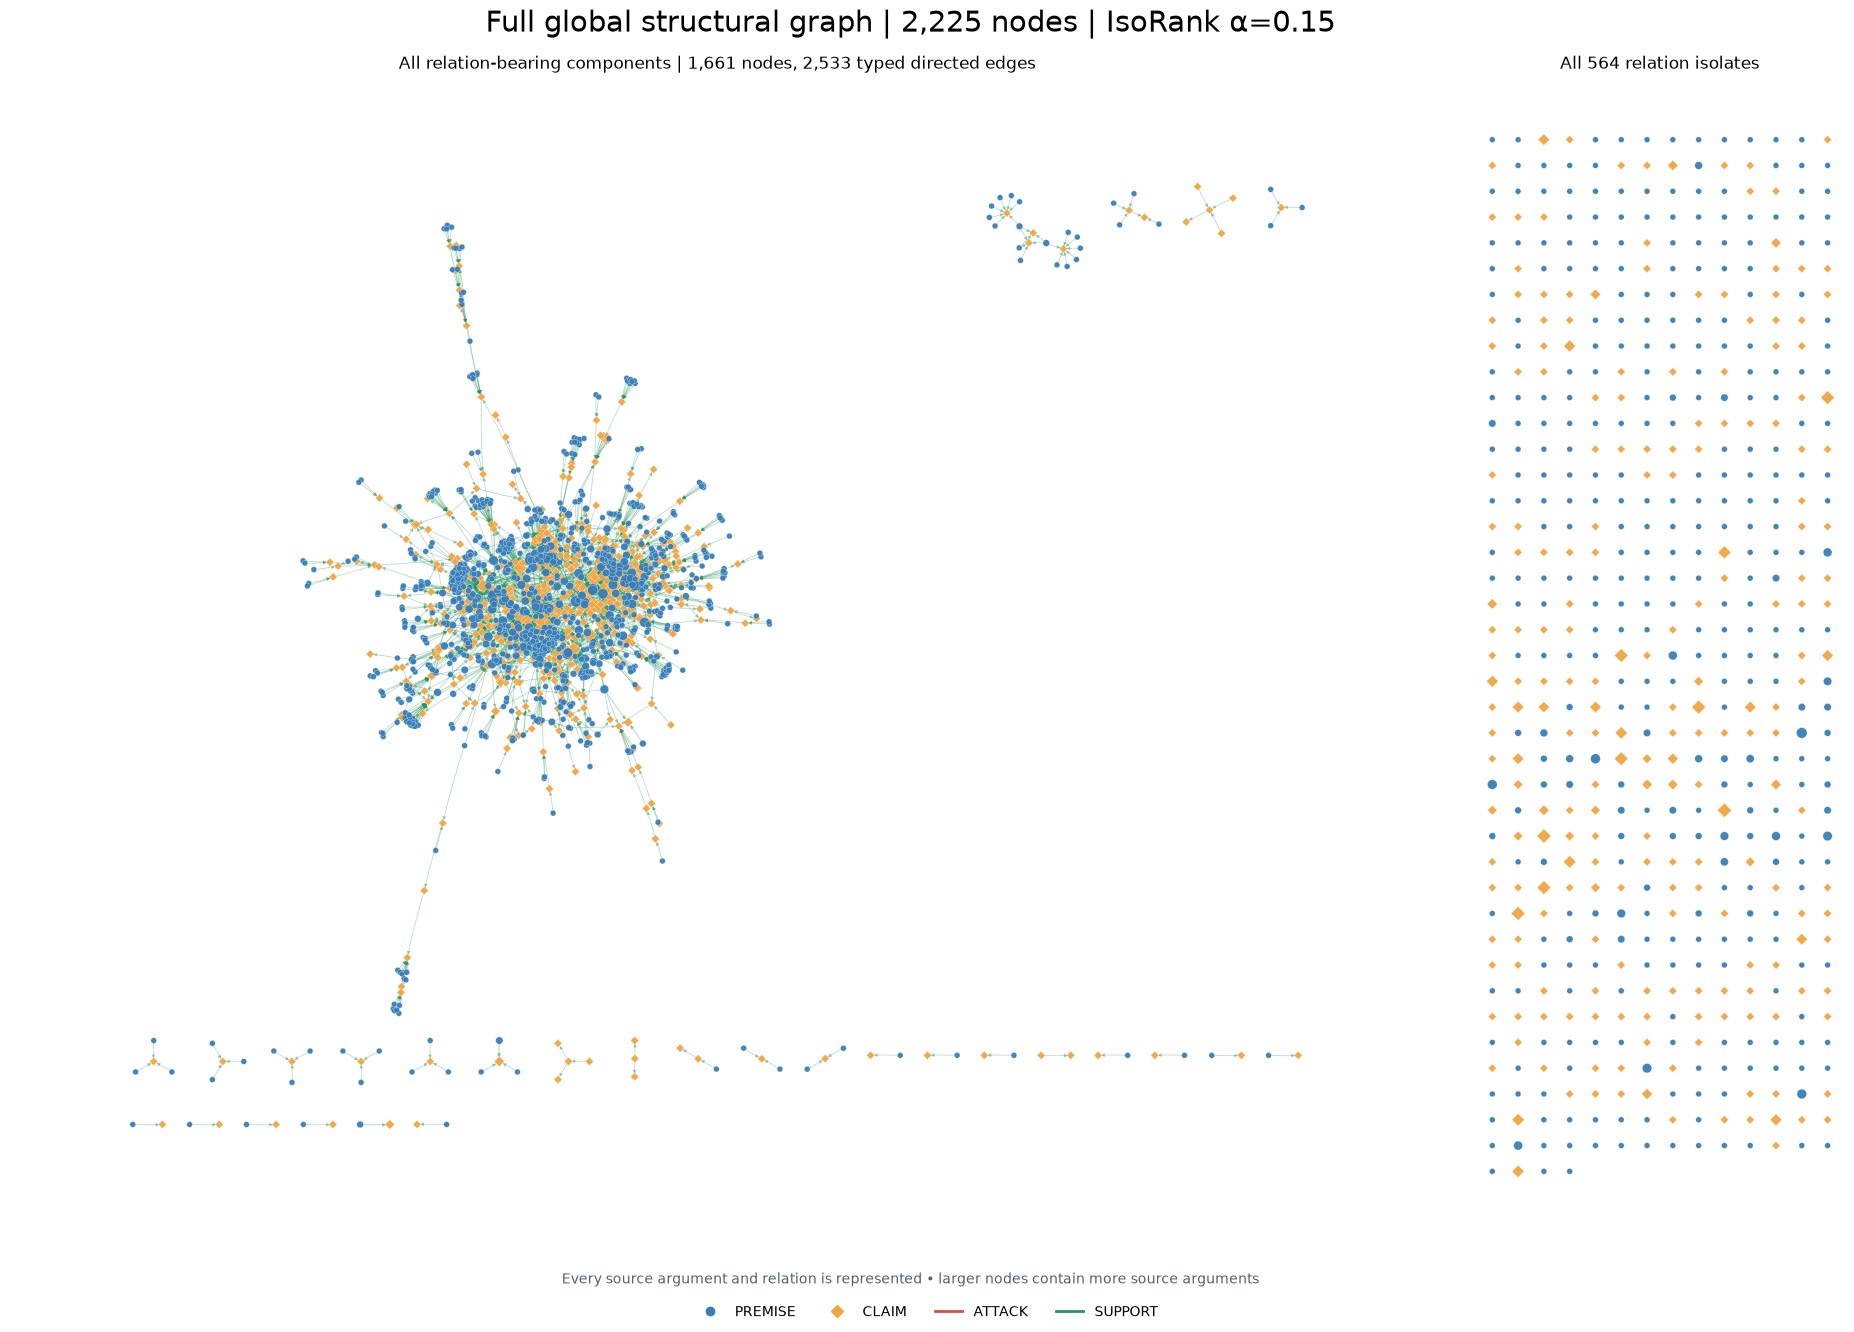

In [11]:
relation_isolates = sorted(nx.isolates(global_graph))
connected_nodes = [node for node in global_graph if node not in set(relation_isolates)]
connected_global_graph = global_graph.subgraph(connected_nodes)
global_positions = packed_component_layout(connected_global_graph)
isolate_columns = max(1, int(np.ceil(np.sqrt(len(relation_isolates) / 3))))
isolate_positions = {
    node: np.asarray([index % isolate_columns, -(index // isolate_columns)], dtype=float)
    for index, node in enumerate(relation_isolates)
}
figure, axes = plt.subplots(1, 2, figsize=(19, 13), gridspec_kw={"width_ratios": [4, 1]}, facecolor="white")
draw_relation_graph(connected_global_graph, global_positions, axes[0])
axes[0].set_title(
    f"All relation-bearing components | {len(connected_nodes):,} nodes, "
    f"{global_graph.number_of_edges():,} typed directed edges", fontsize=12, pad=14,
)
if relation_isolates:
    draw_relation_graph(global_graph.subgraph(relation_isolates), isolate_positions, axes[1])
else:
    axes[1].set_axis_off()
axes[1].set_title(f"All {len(relation_isolates):,} relation isolates", fontsize=12, pad=14)
figure.suptitle(
    f"Full global structural graph | {len(global_nodes):,} nodes | IsoRank α={ISORANK_ALPHA}",
    fontsize=21, y=1.015,
)
figure.legend(handles=legend_handles, loc="lower center", ncol=len(legend_handles), frameon=False)
figure.text(
    0.5, 0.035, "Every source argument and relation is represented • larger nodes contain more source arguments",
    ha="center", fontsize=10, color="#53616e",
)
figure.tight_layout(rect=(0, 0.07, 1, 1))
save_figure(figure, "01_full_global_structural_graph")


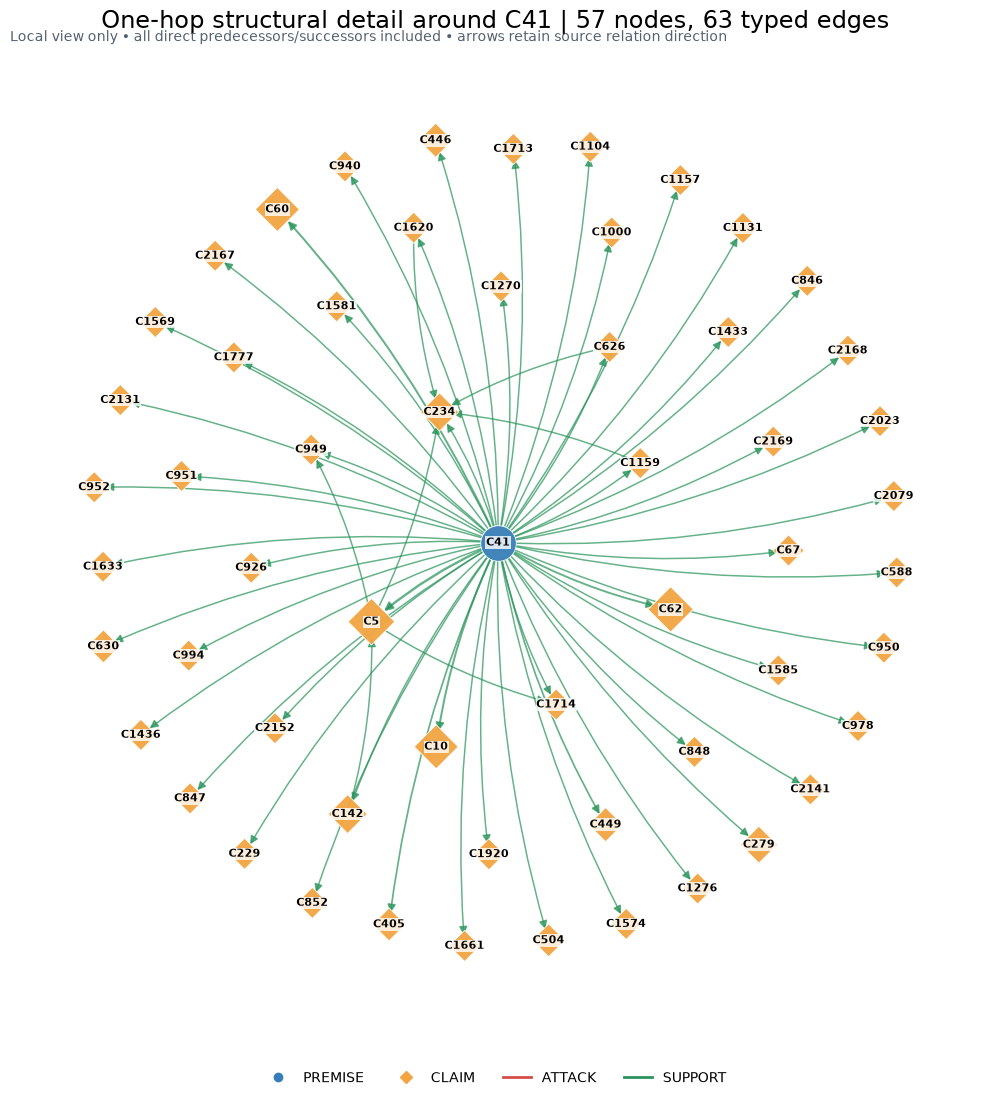

,argument_type,member_count,document_count,text_preview
global_node_id,,,,
C10,CLAIM,21,21,Питання речових доказів вирішити в порядку ст....
C1000,CLAIM,1,1,"приходить до висновку, що необхідним і достатн..."
C1104,CLAIM,1,1,суд ухвалює вирок.
C1131,CLAIM,1,1,"Суд переконався, що укладення угоди є добровіл..."
C1157,CLAIM,1,1,суд визнає винним ОСОБА_3 у вчиненні криміна...
C1159,CLAIM,1,1,йому слід призначити покарання у межах санкції...
C1270,CLAIM,1,1,обмежившись згідно ч. 2 ст. 382 КПК України за...
C1276,CLAIM,1,1,Процесуальні витрати у даному кримінальному пр...
C142,CLAIM,9,9,Вивчивши обвинувальний акт та матеріали кримін...


In [12]:
# Explicitly local view: include EVERY predecessor/successor of the selected merged node.
DETAIL_CENTER = max(
    connected_nodes,
    key=lambda node: (global_graph.nodes[node]["member_count"], global_graph.degree(node)),
)
detail_nodes = {DETAIL_CENTER, *global_graph.predecessors(DETAIL_CENTER), *global_graph.successors(DETAIL_CENTER)}
detail_graph = global_graph.subgraph(sorted(detail_nodes)).copy()
detail_positions = nx.kamada_kawai_layout(detail_graph.to_undirected(), weight=None)
figure, ax = plt.subplots(figsize=(15, 11), facecolor="white")
draw_relation_graph(detail_graph, detail_positions, ax, detail=True, labels={node: node for node in detail_graph})
ax.set_title(
    f"One-hop structural detail around {DETAIL_CENTER} | "
    f"{len(detail_graph)} nodes, {detail_graph.number_of_edges()} typed edges",
    fontsize=17, pad=20,
)
ax.text(
    0.0, 1.015,
    "Local view only • all direct predecessors/successors included • arrows retain source relation direction",
    transform=ax.transAxes, fontsize=10, color="#53616e",
)
figure.legend(handles=legend_handles, loc="lower center", ncol=len(legend_handles), frameon=False)
figure.tight_layout(rect=(0, 0.045, 1, 1))
save_figure(figure, "02_global_structural_neighborhood")

detail_table = global_nodes.loc[sorted(detail_nodes), [
    "argument_type", "member_count", "document_count", "representative_text",
]].copy()
detail_table["text_preview"] = detail_table.pop("representative_text").str.slice(0, 180)
display(detail_table.head(25))


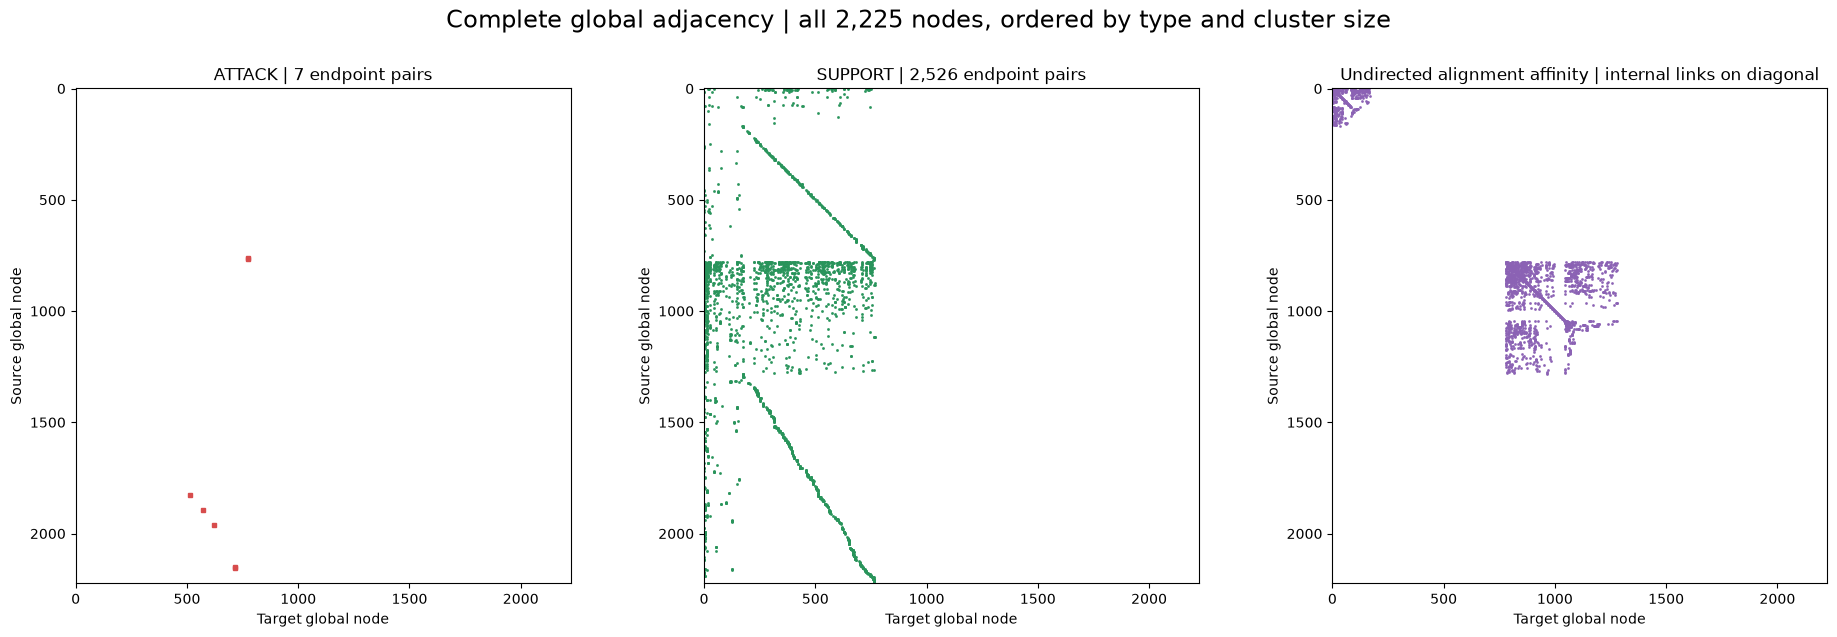

In [13]:
# Full adjacency for both relation types and the separate alignment layer.
adjacency_nodes = list(global_nodes.sort_values(
    ["argument_type", "member_count", "cluster_id"], ascending=[True, False, True],
).index)
adjacency_index = {node: index for index, node in enumerate(adjacency_nodes)}
relation_adjacencies = {}
for relation, edges in global_edges.groupby("relation"):
    relation_adjacencies[relation] = sparse.coo_matrix((
        edges["occurrences"].to_numpy(),
        (edges["source"].map(adjacency_index), edges["target"].map(adjacency_index)),
    ), shape=(len(global_nodes), len(global_nodes))).tocsr()
    assert int(relation_adjacencies[relation].sum()) == int((relations_df["relation"] == relation).sum())
contracted_affinity_adjacency = nx.to_scipy_sparse_array(
    global_affinity_graph, nodelist=adjacency_nodes, weight="occurrences", format="csr",
)
figure, axes = plt.subplots(1, len(relation_adjacencies) + 1, figsize=(19, 6), facecolor="white")
for ax, (relation, matrix) in zip(axes, sorted(relation_adjacencies.items())):
    ax.spy(matrix, markersize=2.3 if relation == "ATTACK" else 0.9,
           color=RELATION_COLORS.get(relation, "#8794a2"))
    ax.set_title(f"{relation} | {matrix.nnz:,} endpoint pairs", fontsize=12)
axes[-1].spy(contracted_affinity_adjacency, markersize=0.85, color=AFFINITY_COLOR)
axes[-1].set_title("Undirected alignment affinity | internal links on diagonal", fontsize=12)
for ax in axes:
    ax.xaxis.tick_bottom()
    ax.set_xlabel("Target global node")
    ax.set_ylabel("Source global node")
figure.suptitle(
    f"Complete global adjacency | all {len(global_nodes):,} nodes, ordered by type and cluster size",
    fontsize=17, y=1.03,
)
figure.tight_layout()
save_figure(figure, "03_complete_global_adjacency")


### Interactive global graph

Zoom and hover to inspect every node and typed relation. SUPPORT and ATTACK are directed: the relation hover explicitly shows `source → target`. Toggle **Alignment affinity** in the legend to show the separate undirected links. Internal affinity is summarized in node hover; complete internal-link evidence remains in the exported graph. All nodes, including relation isolates, appear in this view.

In [14]:
import html
import textwrap
import plotly.graph_objects as go

# Reuse the full relation layout and place isolates in a separate band to its right.
interactive_positions = {node: point.copy() for node, point in global_positions.items()}
if relation_isolates:
    x_offset = max((point[0] for point in global_positions.values()), default=0) + 4
    y_top = max((point[1] for point in global_positions.values()), default=0)
    for node, point in isolate_positions.items():
        interactive_positions[node] = point * 0.7 + [x_offset, y_top]
assert set(interactive_positions) == set(global_graph)

interactive_figure = go.Figure()
for relation, edges in global_edges.groupby("relation", sort=True):
    xs, ys, mid_x, mid_y, edge_hover = [], [], [], [], []
    for edge in edges.itertuples(index=False):
        start, end = interactive_positions[edge.source], interactive_positions[edge.target]
        xs.extend([float(start[0]), float(end[0]), None])
        ys.extend([float(start[1]), float(end[1]), None])
        mid_x.append(float((start[0] + end[0]) / 2))
        mid_y.append(float((start[1] + end[1]) / 2))
        edge_hover.append(
            f"{edge.source} → {edge.target}<br>{relation}<br>"
            f"{edge.occurrences} source relations; {edge.document_count} documents<br>"
            f"Confidence mean: {edge.confidence_mean:.3f}; sum: {edge.weight:.3f}"
        )
    color = RELATION_COLORS.get(relation, "#8794a2")
    interactive_figure.add_trace(go.Scattergl(
        x=xs, y=ys, mode="lines", line={"color": color, "width": 0.8},
        opacity=0.35, name=relation, legendgroup=relation, hoverinfo="skip",
    ))
    interactive_figure.add_trace(go.Scattergl(
        x=mid_x, y=mid_y, mode="markers",
        marker={"size": 4, "color": color, "opacity": 0.3},
        hovertext=edge_hover, hovertemplate="%{hovertext}<extra></extra>",
        name=relation + " evidence", legendgroup=relation, showlegend=False,
    ))

affinity_x, affinity_y = [], []
for source, target in global_affinity_graph.edges():
    if source != target:
        start, end = interactive_positions[source], interactive_positions[target]
        affinity_x.extend([float(start[0]), float(end[0]), None])
        affinity_y.extend([float(start[1]), float(end[1]), None])
interactive_figure.add_trace(go.Scattergl(
    x=affinity_x, y=affinity_y, mode="lines",
    line={"color": AFFINITY_COLOR, "width": 0.7, "dash": "dot"},
    opacity=0.4, name="Alignment affinity (undirected)", visible="legendonly", hoverinfo="skip",
))

for argument_type, rows in global_nodes.groupby("argument_type", sort=True):
    ids = rows.index.tolist()
    hover = []
    for node in ids:
        data = global_graph.nodes[node]
        internal = global_affinity_graph.get_edge_data(node, node, {}).get("occurrences", 0)
        preview = "<br>".join(html.escape(line) for line in textwrap.wrap(data["representative_text"][:420], 85))
        hover.append(
            f"<b>{node}: {argument_type}</b><br>{data['member_count']} source arguments / "
            f"{data['document_count']} documents<br>Internal affinity links: {internal}<br>{preview}"
        )
    interactive_figure.add_trace(go.Scattergl(
        x=[float(interactive_positions[node][0]) for node in ids],
        y=[float(interactive_positions[node][1]) for node in ids],
        mode="markers", name=argument_type,
        marker={
            "size": [4 + 3 * np.log1p(global_graph.nodes[node]["member_count"]) for node in ids],
            "color": NODE_COLORS.get(argument_type, "#999999"),
            "symbol": "diamond" if argument_type == "CLAIM" else "circle",
            "line": {"color": "white", "width": 0.5},
        },
        hovertext=hover, hovertemplate="%{hovertext}<extra></extra>",
    ))
interactive_figure.update_layout(
    title=f"Full global structural graph · {len(global_nodes):,} nodes · α={ISORANK_ALPHA}",
    template="plotly_white", height=850, dragmode="pan", hovermode="closest",
    xaxis={"visible": False}, yaxis={"visible": False, "scaleanchor": "x", "scaleratio": 1},
    legend={"orientation": "h", "y": -0.02}, margin={"l": 10, "r": 10, "t": 65, "b": 70},
)
interactive_figure.show()
interactive_figure.write_html(ARTIFACT_DIR / "04_interactive_global_graph.html", include_plotlyjs=True)


## Export the complete graph and alignment data

The compressed JSON bundle contains the relation multigraph, the undirected affinity graph, every original source document, and the partition records. Arrays preserve the full dense `H`, sparse `H_graph`, individual text/section embeddings, and source ordering. Parquet files provide convenient flat tables. Non-finite diagnostic conductance values are represented as JSON `null`; they remain unchanged in the Parquet diagnostics.

These exports allow reconstruction of the full graph and inspection of every member or relation without relying on plot labels or truncated text previews.

In [15]:
import importlib.metadata

def json_safe(value):
    if isinstance(value, dict):
        return {str(key): json_safe(item) for key, item in value.items()}
    if isinstance(value, (list, tuple)):
        return [json_safe(item) for item in value]
    if isinstance(value, np.ndarray):
        return json_safe(value.tolist())
    if isinstance(value, np.generic):
        return json_safe(value.item())
    if value is pd.NA or (isinstance(value, float) and not np.isfinite(value)):
        return None
    return value

manifest = {
    "source_notebook": SOURCE_NOTEBOOK.name,
    "source_notebook_sha256": SOURCE_SHA256_BEFORE,
    "alignment_profile": ALIGNMENT_PROFILE,
    "isorank_alpha": ISORANK_ALPHA,
    "minimum_similarity": MIN_SIMILARITY,
    "k_neighbors": K_NEIGHBORS,
    "isorank_tolerance": ISORANK_TOL,
    "isorank_max_iterations": ISORANK_MAX_ITER,
    "partition_config": asdict(PARTITION_CONFIG),
    "embedding_batch_size": EMBEDDING_BATCH_SIZE,
    "device": str(DEVICE),
    "python": sys.version,
    "packages": {name: importlib.metadata.version(name) for name in [
        "numpy", "pandas", "torch", "transformers", "scipy", "networkx", "matplotlib",
    ]},
    "dense_H_sha256": h_digest,
    "partition_sha256": cluster_digest,
    "document_ids": paragraph_dataset_mini,
    "source_document_sha256": {
        document_id: hashlib.sha256((DATA_DIR / f"{document_id}.json").read_bytes()).hexdigest()
        for document_id in paragraph_dataset_mini
    },
    "pipeline_module_sha256": {
        path.name: hashlib.sha256(path.read_bytes()).hexdigest()
        for path in sorted((PROJECT_ROOT / "src/legal_data_doc_parts/argument_graph").glob("*.py"))
    },
    "summary": global_summary.to_dict(),
    "relation_weight_semantics": "sum of source confidence values, not a probability",
    "affinity_semantics": "undirected alignment evidence, separate from typed relations",
}
bundle = json_safe({
    "manifest": manifest,
    "relation_graph": nx.node_link_data(global_graph),
    "affinity_graph": nx.node_link_data(global_affinity_graph),
    "partition": clusters,
    "source_documents": dataset.documents,
})
with gzip.open(ARTIFACT_DIR / "global_graph_bundle.json.gz", "wt", encoding="utf-8") as stream:
    json.dump(bundle, stream, ensure_ascii=False, allow_nan=False)

np.savez_compressed(
    ARTIFACT_DIR / "alignment_arrays.npz",
    H=H, offsets=offsets,
    text_embeddings=text_embedding_array,
    section_embeddings=section_embedding_array,
    section_present=section_present.detach().cpu().numpy(),
    node_to_cluster=global_members["cluster_id"].to_numpy(),
    centroid_embeddings=np.asarray([
        global_graph.nodes[node]["centroid_embedding"] for node in global_nodes.index
    ]),
)
sparse.save_npz(ARTIFACT_DIR / "source_affinity_graph.npz", H_graph)
global_members.drop(columns="raw_component").to_parquet(ARTIFACT_DIR / "global_members.parquet", index=False)
global_relation_evidence.drop(columns="raw_relation").to_parquet(
    ARTIFACT_DIR / "relation_evidence.parquet", index=False,
)
global_nodes.to_parquet(ARTIFACT_DIR / "global_nodes.parquet")
global_edges.to_parquet(ARTIFACT_DIR / "global_relation_edges.parquet", index=False)
global_affinity_evidence.to_parquet(ARTIFACT_DIR / "affinity_evidence.parquet", index=False)
global_affinity_edges.to_parquet(ARTIFACT_DIR / "global_affinity_edges.parquet", index=False)
partition_diagnostics.to_parquet(ARTIFACT_DIR / "partition_diagnostics.parquet", index=False)
alignment_diagnostics.to_parquet(ARTIFACT_DIR / "alignment_diagnostics.parquet", index=False)
pd.DataFrame.from_dict(global_positions, orient="index", columns=["x", "y"]).to_parquet(
    ARTIFACT_DIR / "relation_connected_layout.parquet",
)
(ARTIFACT_DIR / "manifest.json").write_text(
    json.dumps(json_safe(manifest), ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8",
)

# Round-trip checks on the actual saved artifacts.
with gzip.open(ARTIFACT_DIR / "global_graph_bundle.json.gz", "rt", encoding="utf-8") as stream:
    reloaded_bundle = json.load(stream)
reloaded_graph = nx.node_link_graph(reloaded_bundle["relation_graph"])
assert reloaded_graph.number_of_nodes() == len(global_nodes)
assert reloaded_graph.number_of_edges() == len(global_edges)
assert sum(data["member_count"] for _, data in reloaded_graph.nodes(data=True)) == len(arguments_df)
assert sum(len(data["evidence"]) for _, _, data in reloaded_graph.edges(data=True)) == len(relations_df)
assert reloaded_bundle["source_documents"] == dataset.documents
assert hashlib.sha256(SOURCE_NOTEBOOK.read_bytes()).hexdigest() == SOURCE_SHA256_BEFORE
with np.load(ARTIFACT_DIR / "alignment_arrays.npz") as arrays:
    assert np.array_equal(arrays["node_to_cluster"], global_members["cluster_id"].to_numpy())
    assert hashlib.sha256(np.ascontiguousarray(arrays["H"]).tobytes()).hexdigest() == h_digest
del reloaded_bundle, reloaded_graph
display(Markdown(
    "**Export and reconstruction checks passed.** The original notebook is unchanged. "
    f"[Open interactive graph]({ARTIFACT_DIR.name}/04_interactive_global_graph.html) · "
    f"[Full graph bundle]({ARTIFACT_DIR.name}/global_graph_bundle.json.gz) · "
    f"[Reproducibility manifest]({ARTIFACT_DIR.name}/manifest.json)"
))
display(pd.DataFrame([
    {"artifact": path.name, "size_MiB": round(path.stat().st_size / 2**20, 3)}
    for path in sorted(ARTIFACT_DIR.iterdir()) if path.is_file()
]))


**Export and reconstruction checks passed.** The original notebook is unchanged. [Open interactive graph](structural_global_graph_artifacts/04_interactive_global_graph.html) · [Full graph bundle](structural_global_graph_artifacts/global_graph_bundle.json.gz) · [Reproducibility manifest](structural_global_graph_artifacts/manifest.json)

,artifact,size_MiB
0,01_full_global_structural_graph.png,0.754
1,01_full_global_structural_graph.svg,2.444
2,02_global_structural_neighborhood.png,0.583
3,02_global_structural_neighborhood.svg,0.119
4,03_complete_global_adjacency.png,0.136
5,03_complete_global_adjacency.svg,0.631
6,04_interactive_global_graph.html,7.627
7,affinity_evidence.parquet,0.080
8,alignment_arrays.npz,40.811
9,alignment_diagnostics.parquet,0.025
